#Câu a Nhập dữ liệu đầu vào và tiền xử lý dữ liệu

In [1]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

# 1. Nhập dữ liệu đầu vào Mushroom
data_path = 'mushrooms.csv'

# Danh sách tên cột chuẩn của tập Mushroom (UCI) nếu đọc file không có tiêu đề
columns = [
    'class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
    'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
    'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
    'stalk-surface-below-ring', 'stalk-color-above-ring',
    'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
    'ring-type', 'spore-print-color', 'population', 'habitat'
]

# Đọc dữ liệu (tự động nhận diện trường hợp file có sẵn header hoặc file không header)
try:
    df_preview = pd.read_csv(data_path, nrows=5, na_values=['?', ' ', 'NA'])
    if 'class' in df_preview.columns:
        data = pd.read_csv(data_path, na_values=['?', ' ', 'NA'])
    elif len(df_preview.columns) == 23:
        data = pd.read_csv(data_path, names=columns, na_values=['?', ' ', 'NA'])
    else:
        data = pd.read_csv(data_path, na_values=['?', ' ', 'NA'])
except Exception as e:
    data = pd.read_csv(data_path, names=columns, na_values=['?', ' ', 'NA'])

print(f"Số lượng dữ liệu ban đầu: {len(data)}")

# 2. Tiền xử lý dữ liệu: xóa các dòng bị thiếu dữ liệu (missing values)
data = data.dropna().reset_index(drop=True)
print(f"Số lượng dữ liệu sau khi xóa dòng trống: {len(data)}")

# Hiển thị thông tin tổng quan của tập dữ liệu
display(data.head())
data.info()


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Số lượng dữ liệu ban đầu: 8124
Số lượng dữ liệu sau khi xóa dòng trống: 5644


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5644 entries, 0 to 5643
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     5644 non-null   object
 1   cap-shape                 5644 non-null   object
 2   cap-surface               5644 non-null   object
 3   cap-color                 5644 non-null   object
 4   bruises                   5644 non-null   object
 5   odor                      5644 non-null   object
 6   gill-attachment           5644 non-null   object
 7   gill-spacing              5644 non-null   object
 8   gill-size                 5644 non-null   object
 9   gill-color                5644 non-null   object
 10  stalk-shape               5644 non-null   object
 11  stalk-root                5644 non-null   object
 12  stalk-surface-above-ring  5644 non-null   object
 13  stalk-surface-below-ring  5644 non-null   object
 14  stalk-color-above-ring  

#Câu 4 Tách features và labels

In [2]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 4. Tách các thuộc tính đặc trưng và thuộc tính quyết định 'class'
features = data.drop('class', axis=1)
labels = data['class']

print(f"Kích thước features: {features.shape}")
print(f"Kích thước labels: {labels.shape}")
print("Phân bố nhãn quyết định class:")
print(labels.value_counts())


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước features: (5644, 22)
Kích thước labels: (5644,)
Phân bố nhãn quyết định class:
class
e    3488
p    2156
Name: count, dtype: int64


#Câu 5 Chuyển đổi các cột phân loại về dạng One-Hot Vector

In [9]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Xác định các thuộc tính không phải dạng số trong biến features
cat_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("features.select_dtypes(exclude=['int64', 'float64']).columns:")
print(cat_cols)

# Chuyển đổi về dạng one-hot vector (nếu có cột object)
features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
display(features_onehot)


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
features.select_dtypes(exclude=['int64', 'float64']).columns:
Index(['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='object')


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_n,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u
0,0,0,0,0,0,1,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
1,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,1,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,1,0,0,0,1,...,0,1,0,0,0,0,0,0,0,1
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5639,1,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
5640,0,0,0,0,0,1,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
5641,0,0,0,0,0,1,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
5642,0,0,0,0,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0


#Câu 6 Tách lại dữ liệu Train và Test như ban đầu

In [10]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn.model_selection import train_test_split

# 6. Sử dụng câu lệnh chia tỷ lệ 70% huấn luyện và 30% kiểm thử theo đề bài
X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)

print(f"Kích thước tập Train: {X_train.shape}, {y_train.shape}")
print(f"Kích thước tập Test: {X_test.shape}, {y_test.shape}")


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước tập Train: (3950, 98), (3950,)
Kích thước tập Test: (1694, 98), (1694,)


#Câu 7 Xây dựng cây quyết định ID3 (Entropy) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy: 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1058
           p       1.00      1.00      1.00       636

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



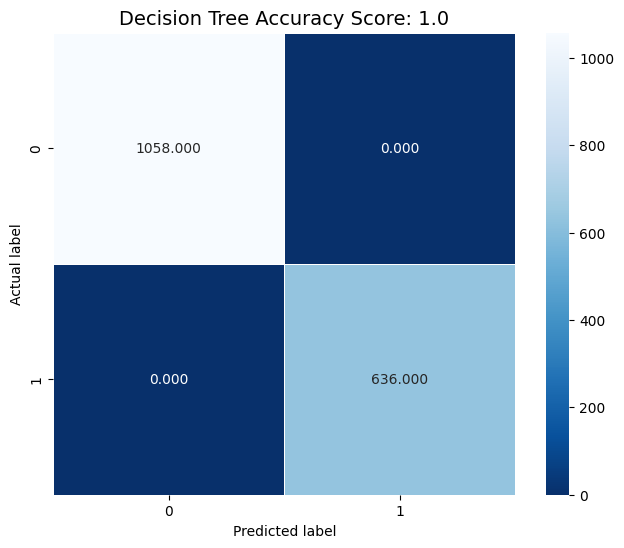

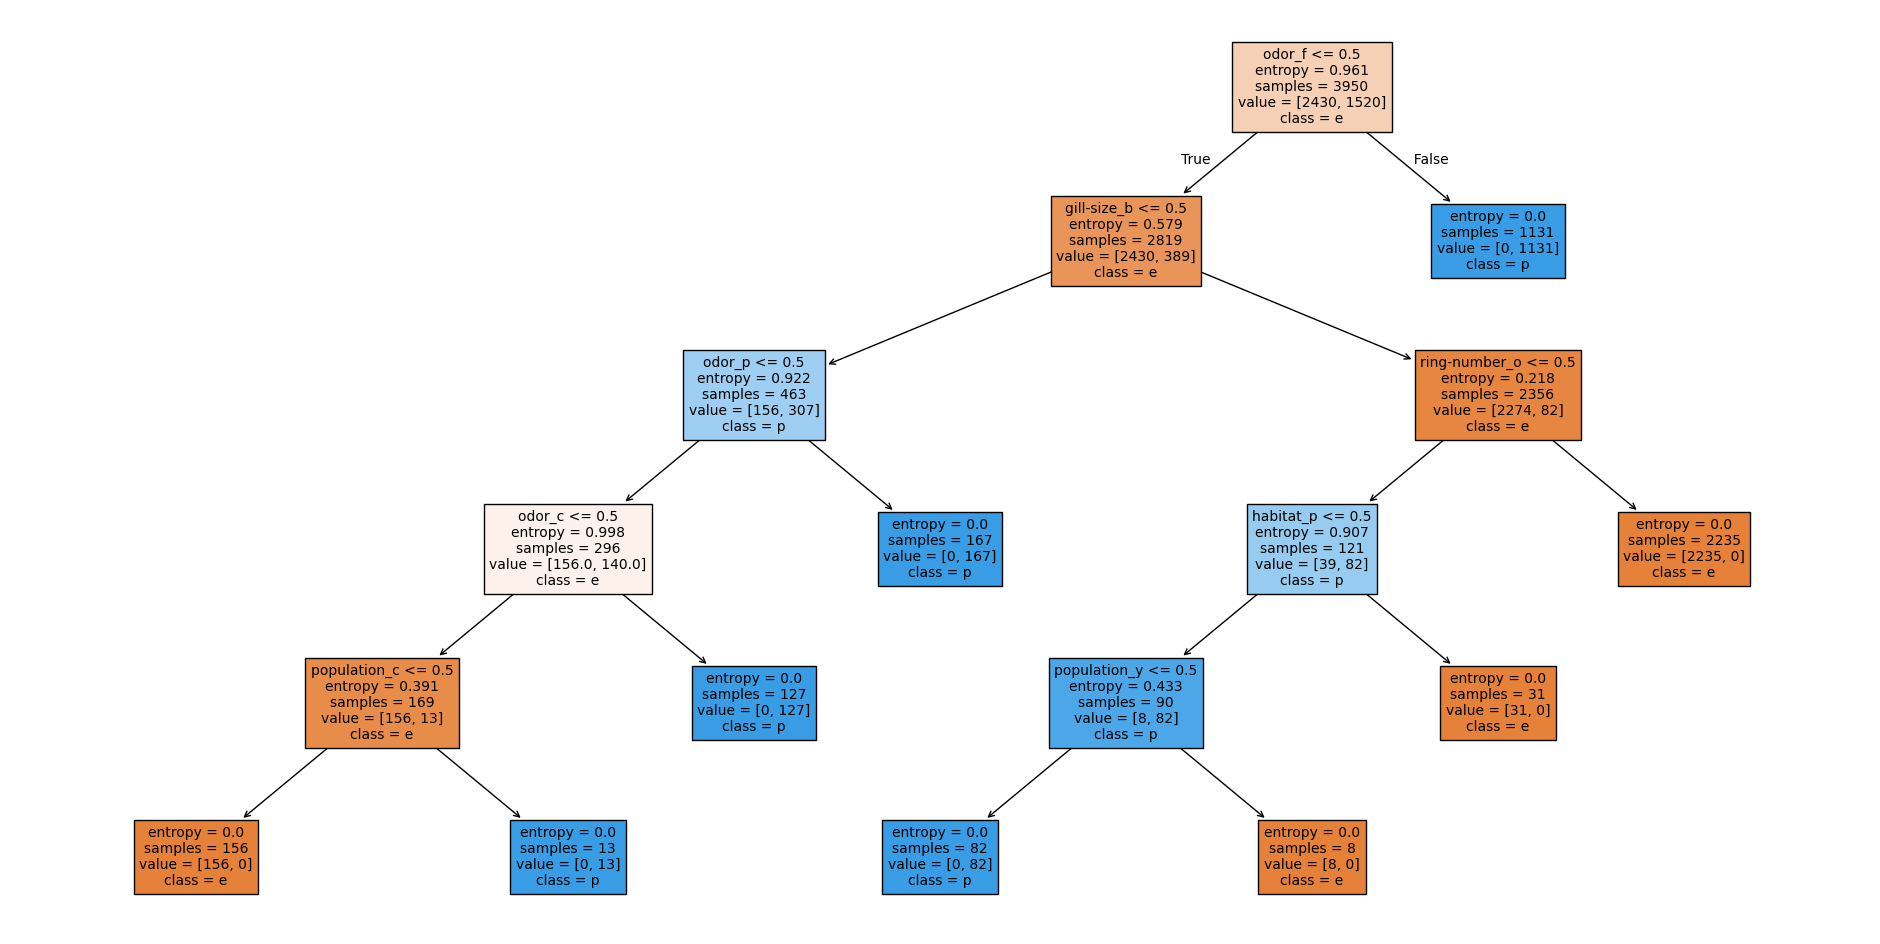

In [5]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

from sklearn import tree, metrics

# 1. Huấn luyện cây ID3 (criterion="entropy")
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

# 2. Đánh giá mô hình trên tập kiểm thử
tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)

print("Accuracy:", tree_score)
print("Report:\n", metrics.classification_report(y_test, tree_pred))

# 3. Tính toán ma trận nhầm lẫn và vẽ heatmap
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree Accuracy Score: {tree_score}', size=14)
plt.show()

# 4. Biểu diễn cây ID3 và lưu ra file ảnh
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf, filled=True, fontsize=10, feature_names=list(features_onehot.columns), class_names=sorted(labels.unique()))
plt.savefig('decision_tree_mushroom.png', dpi=100)
plt.show()


#Câu 8 Xây dựng cây quyết định CART (Gini) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy (CART): 1.0
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1058
           p       1.00      1.00      1.00       636

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



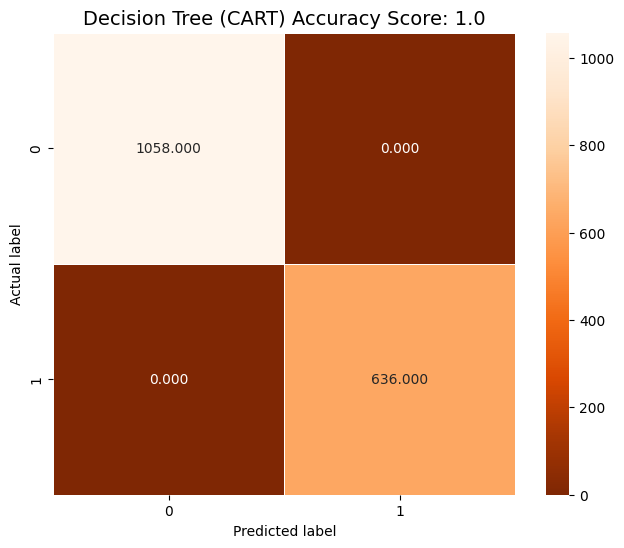

In [6]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 8. Xây dựng cây CART (criterion='gini')
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

# Đánh giá kết quả
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Accuracy (CART):", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Oranges_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (CART) Accuracy Score: {cart_score}', size=14)
plt.show()


#Câu 9 Xây dựng mô hình Naïve Bayes (GaussianNB) và đánh giá

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Accuracy (Naïve Bayes): 0.9976387249114522
Report:
               precision    recall  f1-score   support

           e       1.00      1.00      1.00      1058
           p       0.99      1.00      1.00       636

    accuracy                           1.00      1694
   macro avg       1.00      1.00      1.00      1694
weighted avg       1.00      1.00      1.00      1694



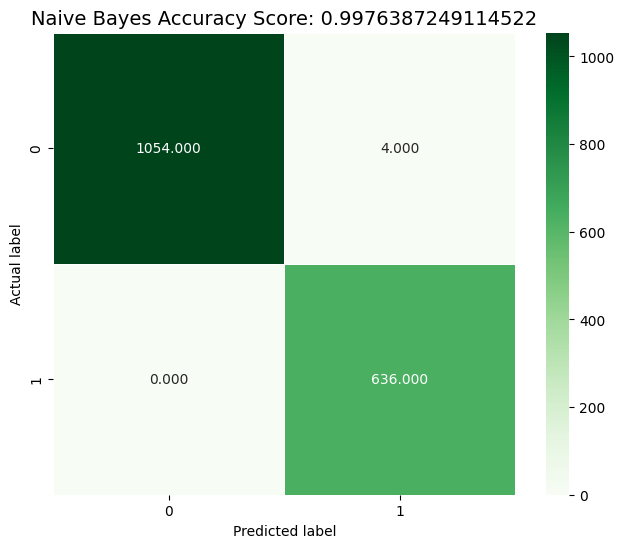

In [7]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 9. Huấn luyện mô hình Naïve Bayes
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)

print("Accuracy (Naïve Bayes):", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

# Ma trận nhầm lẫn
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naive Bayes Accuracy Score: {bayes_score}', size=14)
plt.show()


#Câu 10 So sánh kết quả của các mô hình

In [8]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# 10. Tổng hợp và so sánh kết quả các mô hình (với nhãn dương là 'p' - Poisonous: nấm độc)
pos_cls = 'p' if 'p' in labels.values else labels.unique()[0]
comparison_df = pd.DataFrame({
    'Mô hình': ['Decision Tree (ID3)', 'Decision Tree (CART)', 'Naïve Bayes'],
    'Accuracy': [tree_score, cart_score, bayes_score],
    f'Precision ({pos_cls})': [
        metrics.precision_score(y_test, tree_pred, pos_label=pos_cls),
        metrics.precision_score(y_test, cart_pred, pos_label=pos_cls),
        metrics.precision_score(y_test, bayes_pred, pos_label=pos_cls)
    ],
    f'Recall ({pos_cls})': [
        metrics.recall_score(y_test, tree_pred, pos_label=pos_cls),
        metrics.recall_score(y_test, cart_pred, pos_label=pos_cls),
        metrics.recall_score(y_test, bayes_pred, pos_label=pos_cls)
    ],
    f'F1-score ({pos_cls})': [
        metrics.f1_score(y_test, tree_pred, pos_label=pos_cls),
        metrics.f1_score(y_test, cart_pred, pos_label=pos_cls),
        metrics.f1_score(y_test, bayes_pred, pos_label=pos_cls)
    ]
})

print("--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---")
display(comparison_df)


Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ---


,Mô hình,Accuracy,Precision (p),Recall (p),F1-score (p)
0,Decision Tree (ID3),1.000000,1.00000,1.0,1.000000
1,Decision Tree (CART),1.000000,1.00000,1.0,1.000000
2,Naïve Bayes,0.997639,0.99375,1.0,0.996865
